# Keep teams out of a closed zone

> Remove unsafe or unreachable ground before planning

::: {.callout-note appearance="simple" icon=false}
**How-to guide: get one job done.** It assumes that you know the basics. New to trufl? Take the [tutorial](../tutorials/01_getting_started.ipynb) first. [About the four kinds of page](../explanation/06_documentation.ipynb).
:::

**You need:** `areas`, their `state`, the `directions` and `weights` of [your priorities](03_set_priorities.ipynb), and the closed ground as one polygon, `zone`, in the coordinate system of the areas.

:::{.callout-warning}
trufl knows nothing about safety. Have someone who knows the ground check the final map before a team leaves.
:::

In [ ]:
#| hide
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import geopandas as gpd
from fastcore.test import test_eq

from trufl.utils import gridder
from trufl.callbacks import State, MaxCB, MinCB, StdCB, CountCB, PriorCB
from trufl.optimizer import Optimizer
from trufl.sampler import Sampler, rank_to_sample
from trufl.collector import DataCollector

fname_raster = '../files/ground-truth-01-4326-simulated.tif'
areas = gridder(fname_raster)
no_samples = gpd.GeoDataFrame(index=pd.Index([], name='loc_id'), geometry=None, data={'value': None})
prior_state = State(no_samples, areas, cbs=[PriorCB(fname_raster)])()
first_ranks = Optimizer(prior_state).get_rank(is_benefit_x=[True], w_vector=[1], s_method='CP')
first_n = rank_to_sample(first_ranks['rank'].reindex(areas.index).to_numpy(), budget=600, min=1, policy='quantiles')
measurements = DataCollector(fname_raster).collect(
    Sampler(areas).sample(first_n, method='uniform', rng=np.random.default_rng(0)))
state = State(measurements, areas, cbs=[MaxCB(), MinCB(), StdCB(), CountCB(), PriorCB(fname_raster)])()
ranks = Optimizer(state).get_rank(is_benefit_x=[True, True, True, False, True],
                                  w_vector=[0.25, 0.125, 0.125, 0.25, 0.25], n_method='LINEAR1', s_method='CP')

from shapely.geometry import Point
zone = Point(-1.112, 43.295).buffer(0.024)
directions, weights = [True, True, True, False, True], [0.25, 0.125, 0.125, 0.25, 0.25]

## 1. Cut the zone out

In [ ]:
open_areas = areas.copy()
open_areas['geometry'] = areas.geometry.difference(zone)
open_areas = open_areas[~open_areas.geometry.is_empty]

## 2. Close areas with too little ground left

A nearly closed area would still get its full number of samples, crowded into a sliver. Choose the smallest share of open ground that you accept, here a quarter:

In [ ]:
metric = areas.estimate_utm_crs()
open_share = open_areas.to_crs(metric).area / areas.loc[open_areas.index].to_crs(metric).area
open_areas = open_areas[open_share >= 0.25]
print(len(areas) - len(open_areas), 'areas closed')

11 areas closed


## 3. Rank, allocate and place on what remains

Do all three again. If you only delete points from an existing plan, you lose part of the budget.

In [ ]:
import numpy as np
from trufl.optimizer import Optimizer
from trufl.sampler import Sampler, rank_to_sample

open_ranks = Optimizer(state.loc[open_areas.index]).get_rank(
    is_benefit_x=directions, w_vector=weights, n_method='LINEAR1', s_method='CP')
open_n = rank_to_sample(open_ranks['rank'].reindex(open_areas.index).to_numpy(), budget=400, min=1, policy='quantiles')
plan = Sampler(open_areas).sample(open_n, method='uniform', rng=np.random.default_rng(0))

## 4. Check the result

382 of 400 samples, none in the closed zone


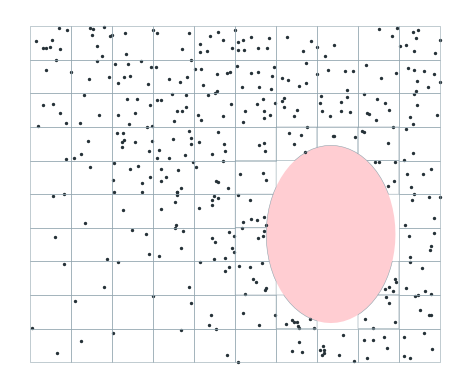

In [ ]:
assert not plan.explode(index_parts=False).within(zone).any(), 'a point is in the closed zone'
print(open_n.sum(), 'of 400 samples, none in the closed zone')

ax = gpd.GeoSeries([zone], crs=areas.crs).plot(color='#FFCDD2')
open_areas.boundary.plot(ax=ax, color='#90A4AE', lw=0.4)
plan.plot(ax=ax, color='#263238', markersize=2)
ax.set_axis_off()

If the total is not your budget, [fit the plan to it](04_fit_budget.ipynb), with `open_areas` and `open_ranks` as `areas` and `ranks`.